Name : Raj Patkar

Roll.no : 23102A0013

Sub : R Programming

# Statistical Analysis of Palmer Penguins

In [2]:
# Install and load required packages
install.packages(c("palmerpenguins", "ggplot2", "dplyr", "moments"),
                 repos = "https://cloud.r-project.org")

library(palmerpenguins)
library(ggplot2)
library(dplyr)
library(moments)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



## Load and inspect the dataset

In [3]:
data("penguins")
df <- penguins %>%
  filter(!is.na(body_mass_g), !is.na(flipper_length_mm), !is.na(species), !is.na(sex))

head(df)
dim(df)
str(df)
summary(df)

species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
<fct>,<fct>,<dbl>,<dbl>,<int>,<int>,<fct>,<int>
Adelie,Torgersen,39.1,18.7,181,3750,male,2007
Adelie,Torgersen,39.5,17.4,186,3800,female,2007
Adelie,Torgersen,40.3,18.0,195,3250,female,2007
Adelie,Torgersen,36.7,19.3,193,3450,female,2007
Adelie,Torgersen,39.3,20.6,190,3650,male,2007
Adelie,Torgersen,38.9,17.8,181,3625,female,2007


[1] 333   8

tibble [333 × 8] (S3: tbl_df/tbl/data.frame)
 $ species          : Factor w/ 3 levels "Adelie","Chinstrap",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ island           : Factor w/ 3 levels "Biscoe","Dream",..: 3 3 3 3 3 3 3 3 3 3 ...
 $ bill_length_mm   : num [1:333] 39.1 39.5 40.3 36.7 39.3 38.9 39.2 41.1 38.6 34.6 ...
 $ bill_depth_mm    : num [1:333] 18.7 17.4 18 19.3 20.6 17.8 19.6 17.6 21.2 21.1 ...
 $ flipper_length_mm: int [1:333] 181 186 195 193 190 181 195 182 191 198 ...
 $ body_mass_g      : int [1:333] 3750 3800 3250 3450 3650 3625 4675 3200 3800 4400 ...
 $ sex              : Factor w/ 2 levels "female","male": 2 1 1 1 2 1 2 1 2 2 ...
 $ year             : int [1:333] 2007 2007 2007 2007 2007 2007 2007 2007 2007 2007 ...


      species          island    bill_length_mm  bill_depth_mm  
 Adelie   :146   Biscoe   :163   Min.   :32.10   Min.   :13.10  
 Chinstrap: 68   Dream    :123   1st Qu.:39.50   1st Qu.:15.60  
 Gentoo   :119   Torgersen: 47   Median :44.50   Median :17.30  
                                 Mean   :43.99   Mean   :17.16  
                                 3rd Qu.:48.60   3rd Qu.:18.70  
                                 Max.   :59.60   Max.   :21.50  
 flipper_length_mm  body_mass_g       sex           year     
 Min.   :172       Min.   :2700   female:165   Min.   :2007  
 1st Qu.:190       1st Qu.:3550   male  :168   1st Qu.:2007  
 Median :197       Median :4050                Median :2008  
 Mean   :201       Mean   :4207                Mean   :2008  
 3rd Qu.:213       3rd Qu.:4775                3rd Qu.:2009  
 Max.   :231       Max.   :6300                Max.   :2009  

## Descriptive statistics for body mass

In [4]:
body_mass_stats <- df %>%
  group_by(species) %>%
  summarise(
    n = n(),
    Mean = mean(body_mass_g),
    Median = median(body_mass_g),
    Minimum = min(body_mass_g),
    Maximum = max(body_mass_g),
    Variance = var(body_mass_g),
    SD = sd(body_mass_g),
    Q1 = quantile(body_mass_g, 0.25),
    Q3 = quantile(body_mass_g, 0.75),
    IQR = IQR(body_mass_g),
    Skewness = moments::skewness(body_mass_g),
    Kurtosis = moments::kurtosis(body_mass_g)
  )
body_mass_stats

species,n,Mean,Median,Minimum,Maximum,Variance,SD,Q1,Q3,IQR,Skewness,Kurtosis
<fct>,<int>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Adelie,146,3706.164,3700,2850,4775,210332.4,458.6201,3362.5,4000,637.5,0.2770077,2.411479
Chinstrap,68,3733.088,3700,2700,4800,147713.5,384.3351,3487.5,3950,462.5,0.2419413,3.463681
Gentoo,119,5092.437,5050,3950,6300,251478.3,501.4762,4700.0,5500,800.0,0.0449965,2.242850


## Overall descriptive statistics

In [5]:
overall_stats <- df %>%
  summarise(
    n = n(),
    Mean = mean(body_mass_g),
    Median = median(body_mass_g),
    Minimum = min(body_mass_g),
    Maximum = max(body_mass_g),
    Variance = var(body_mass_g),
    SD = sd(body_mass_g),
    Q1 = quantile(body_mass_g, 0.25),
    Q3 = quantile(body_mass_g, 0.75),
    IQR = IQR(body_mass_g),
    Skewness = moments::skewness(body_mass_g),
    Kurtosis = moments::kurtosis(body_mass_g)
  )
overall_stats

n,Mean,Median,Minimum,Maximum,Variance,SD,Q1,Q3,IQR,Skewness,Kurtosis
<int>,<dbl>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
333,4207.057,4050,2700,6300,648372.5,805.2158,3550,4775,1225,0.4701162,2.259514


## Body mass visualizations

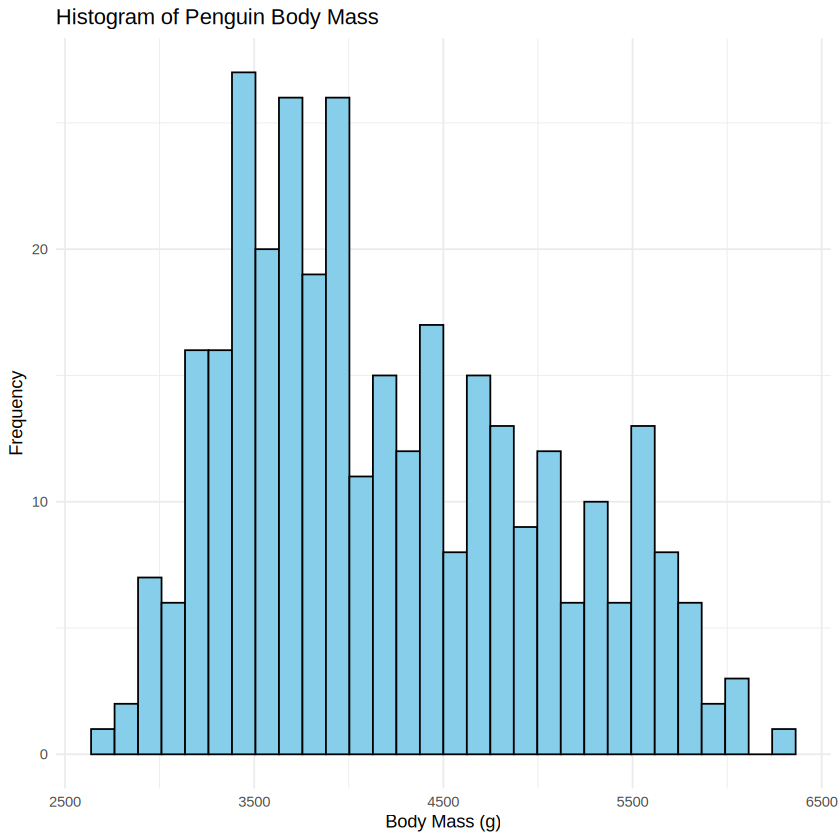

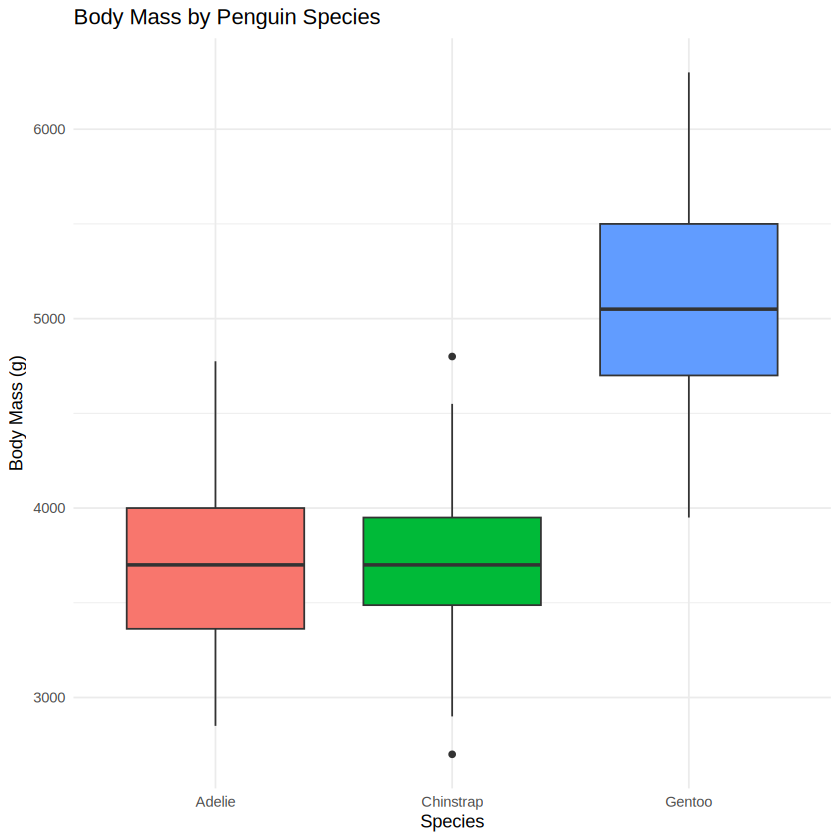

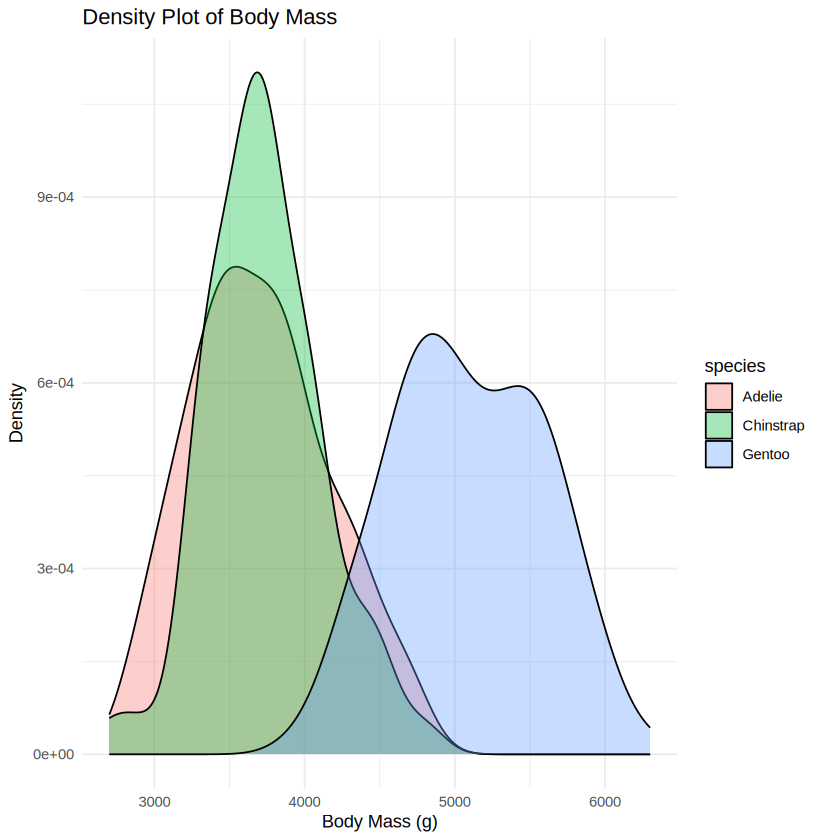

In [6]:
ggplot(df, aes(x = body_mass_g)) +
  geom_histogram(bins = 30, color = "black", fill = "skyblue") +
  labs(title = "Histogram of Penguin Body Mass", x = "Body Mass (g)", y = "Frequency") +
  theme_minimal()

ggplot(df, aes(x = species, y = body_mass_g, fill = species)) +
  geom_boxplot() +
  labs(title = "Body Mass by Penguin Species", x = "Species", y = "Body Mass (g)") +
  theme_minimal() +
  guides(fill = "none")

ggplot(df, aes(x = body_mass_g, fill = species)) +
  geom_density(alpha = 0.35) +
  labs(title = "Density Plot of Body Mass", x = "Body Mass (g)", y = "Density") +
  theme_minimal()

## Hypothesis test: male and female body mass

sex,n,mean,sd
<fct>,<int>,<dbl>,<dbl>
female,165,3862.273,666.1720
male,168,4545.685,787.6289



	Shapiro-Wilk normality test

data:  male_female$body_mass_g[male_female$sex == "male"]
W = 0.92504, p-value = 1.227e-07



	Shapiro-Wilk normality test

data:  male_female$body_mass_g[male_female$sex == "female"]
W = 0.91931, p-value = 6.155e-08



	Welch Two Sample t-test

data:  body_mass_g by sex
t = -8.5545, df = 323.9, p-value = 4.794e-16
alternative hypothesis: true difference in means between group female and group male is not equal to 0
95 percent confidence interval:
 -840.5783 -526.2453
sample estimates:
mean in group female   mean in group male 
            3862.273             4545.685 


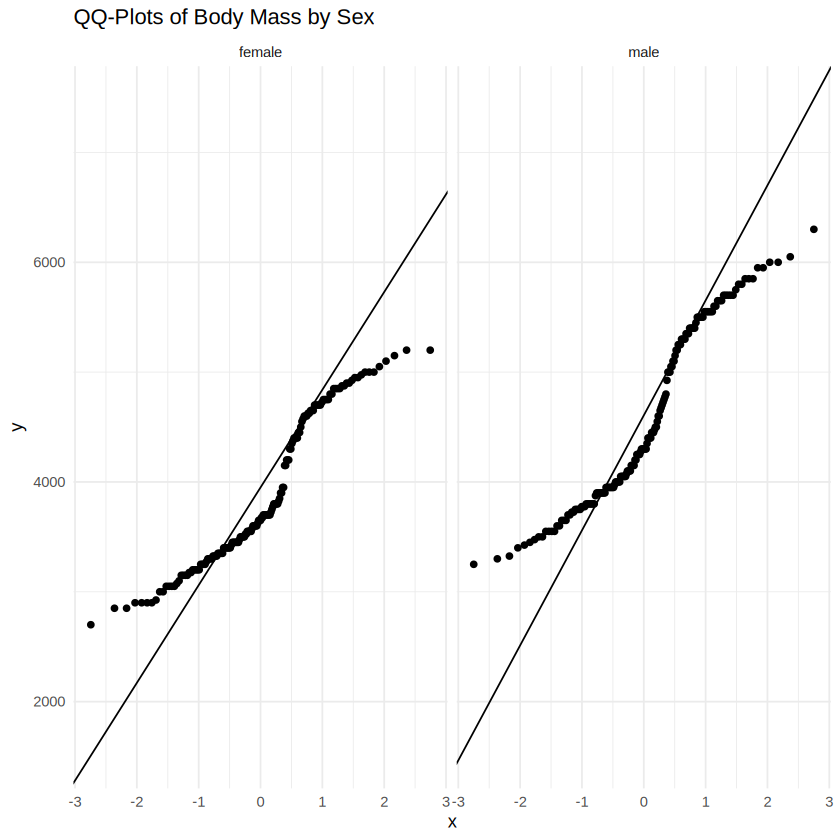

In [7]:
male_female <- df %>% filter(sex %in% c("male", "female"))

# H0: Mean male body mass = mean female body mass
# H1: Mean male body mass != mean female body mass

male_female %>%
  group_by(sex) %>%
  summarise(n = n(), mean = mean(body_mass_g), sd = sd(body_mass_g))

shapiro.test(male_female$body_mass_g[male_female$sex == "male"])
shapiro.test(male_female$body_mass_g[male_female$sex == "female"])

ggplot(male_female, aes(sample = body_mass_g)) +
  stat_qq() +
  stat_qq_line() +
  facet_wrap(~sex) +
  labs(title = "QQ-Plots of Body Mass by Sex") +
  theme_minimal()

t_test_result <- t.test(body_mass_g ~ sex, data = male_female, var.equal = FALSE)
t_test_result

## Cohen's d effect size

In [9]:
# Calculate Cohen's d manually
male <- male_female$body_mass_g[male_female$sex == "male"]
female <- male_female$body_mass_g[male_female$sex == "female"]

n_male <- length(male)
n_female <- length(female)

pooled_sd <- sqrt(
  ((n_male - 1) * var(male) + (n_female - 1) * var(female)) /
  (n_male + n_female - 2)
)

cohen_d <- (mean(male) - mean(female)) / pooled_sd

cat("Cohen's d =", round(cohen_d, 3), "\n")

if(abs(cohen_d) < 0.2) {
  cat("Effect size: Negligible\n")
} else if(abs(cohen_d) < 0.5) {
  cat("Effect size: Small\n")
} else if(abs(cohen_d) < 0.8) {
  cat("Effect size: Medium\n")
} else {
  cat("Effect size: Large\n")
}

Cohen's d = 0.936 
Effect size: Large


## One-way ANOVA: body mass across species

In [11]:
# Levene's test using median-centered absolute deviations
df$abs_dev <- ave(
  df$body_mass_g,
  df$species,
  FUN = function(x) abs(x - median(x))
)

levene_model <- aov(abs_dev ~ species, data = df)
summary(levene_model)

             Df   Sum Sq Mean Sq F value  Pr(>F)   
species       2   716555  358277   5.135 0.00637 **
Residuals   330 23025093   69773                   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

## Tukey HSD post-hoc comparison

In [13]:
# One-way ANOVA
anova_model <- aov(body_mass_g ~ species, data = df)

# ANOVA results
summary(anova_model)

             Df    Sum Sq  Mean Sq F value Pr(>F)    
species       2 145190219 72595110   341.9 <2e-16 ***
Residuals   330  70069447   212332                   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

  Tukey multiple comparisons of means
    95% family-wise confidence level

Fit: aov(formula = body_mass_g ~ species, data = df)

$species
                       diff       lwr       upr    p adj
Chinstrap-Adelie   26.92385 -132.3528  186.2005 0.916431
Gentoo-Adelie    1386.27259 1252.2897 1520.2554 0.000000
Gentoo-Chinstrap 1359.34874 1194.4304 1524.2671 0.000000


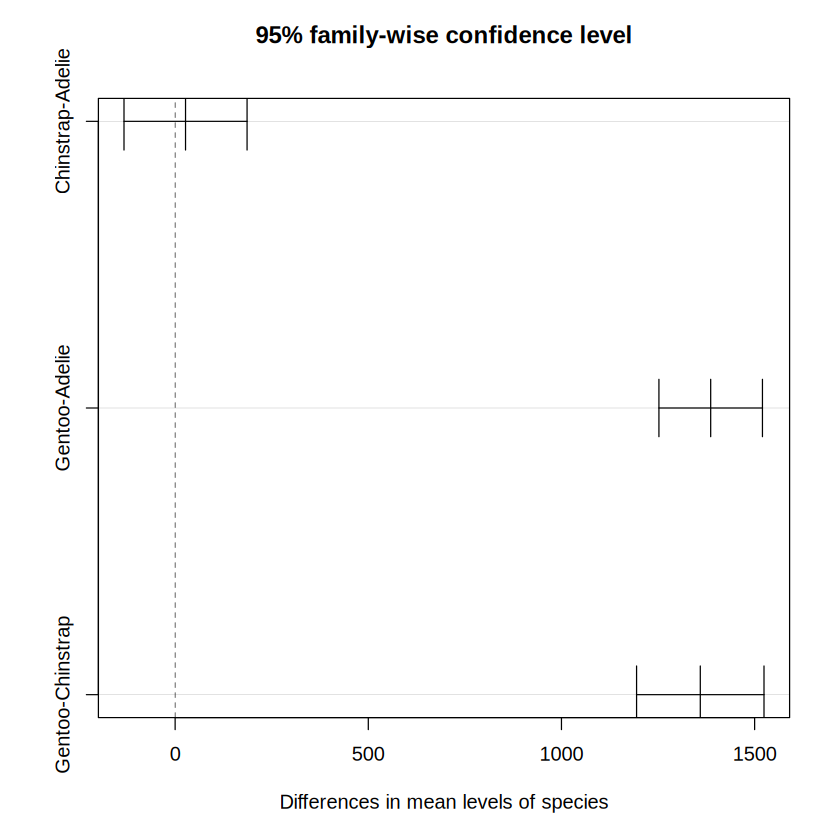

In [14]:
# Tukey HSD post-hoc test
tukey_result <- TukeyHSD(anova_model)

tukey_result

plot(tukey_result)

## Kruskal-Wallis non-parametric test

In [15]:
kruskal_result <- kruskal.test(body_mass_g ~ species, data = df)
kruskal_result


	Kruskal-Wallis rank sum test

data:  body_mass_g by species
Kruskal-Wallis chi-squared = 212.09, df = 2, p-value < 2.2e-16


## ANOVA and Kruskal-Wallis comparison

In [16]:
anova_p <- summary(anova_model)[[1]][["Pr(>F)"]][1]
kruskal_p <- kruskal_result$p.value

comparison <- data.frame(
  Test = c("One-way ANOVA", "Kruskal-Wallis"),
  P_Value = c(anova_p, kruskal_p)
)
comparison

Test,P_Value
<chr>,<dbl>
One-way ANOVA,3.744505e-81
Kruskal-Wallis,8.836877e-47


## Two-way ANOVA: species, sex and their interaction

             Df    Sum Sq  Mean Sq F value   Pr(>F)    
species       2 145190219 72595110 758.358  < 2e-16 ***
sex           1  37090262 37090262 387.460  < 2e-16 ***
species:sex   2   1676557   838278   8.757 0.000197 ***
Residuals   327  31302628    95727                     
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

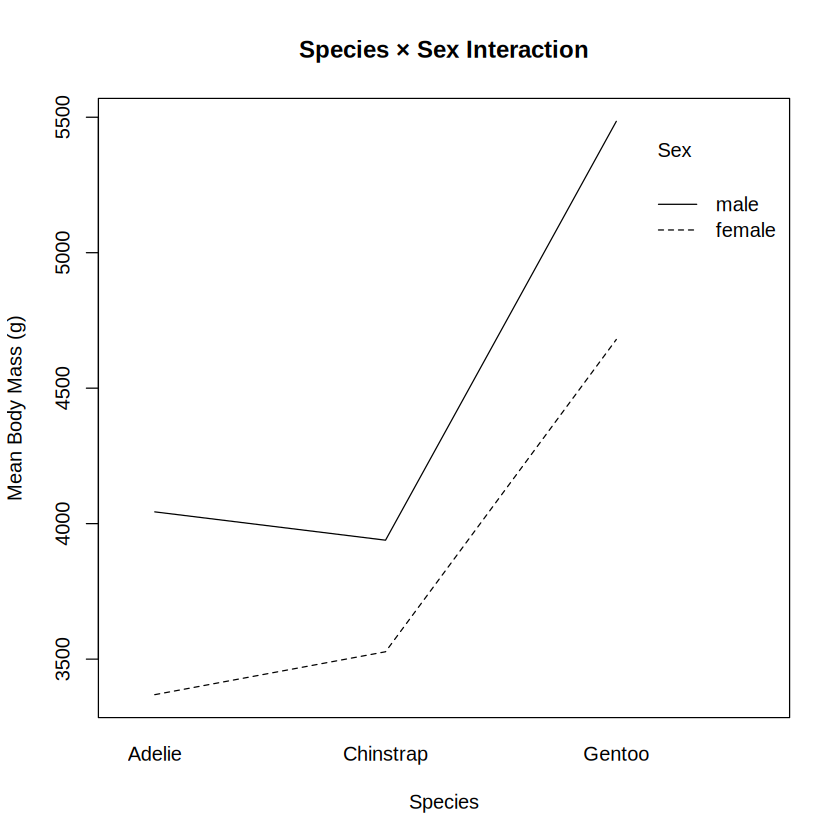

In [17]:
two_way_model <- aov(body_mass_g ~ species * sex, data = df)
summary(two_way_model)

interaction.plot(
  df$species, df$sex, df$body_mass_g,
  xlab = "Species",
  ylab = "Mean Body Mass (g)",
  trace.label = "Sex",
  main = "Species × Sex Interaction"
)

## Flipper length analysis across species

species,n,Mean,Median,SD,Minimum,Maximum
<fct>,<int>,<dbl>,<dbl>,<dbl>,<int>,<int>
Adelie,146,190.1027,190,6.521825,172,210
Chinstrap,68,195.8235,196,7.131894,178,212
Gentoo,119,217.2353,216,6.585431,203,231


             Df Sum Sq Mean Sq F value Pr(>F)    
species       2  50526   25263   567.4 <2e-16 ***
Residuals   330  14693      45                   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

  Tukey multiple comparisons of means
    95% family-wise confidence level

Fit: aov(formula = flipper_length_mm ~ species, data = df)

$species
                     diff       lwr       upr p adj
Chinstrap-Adelie  5.72079  3.414364  8.027215     0
Gentoo-Adelie    27.13255 25.192399 29.072709     0
Gentoo-Chinstrap 21.41176 19.023644 23.799885     0



	Kruskal-Wallis rank sum test

data:  flipper_length_mm by species
Kruskal-Wallis chi-squared = 237.35, df = 2, p-value < 2.2e-16


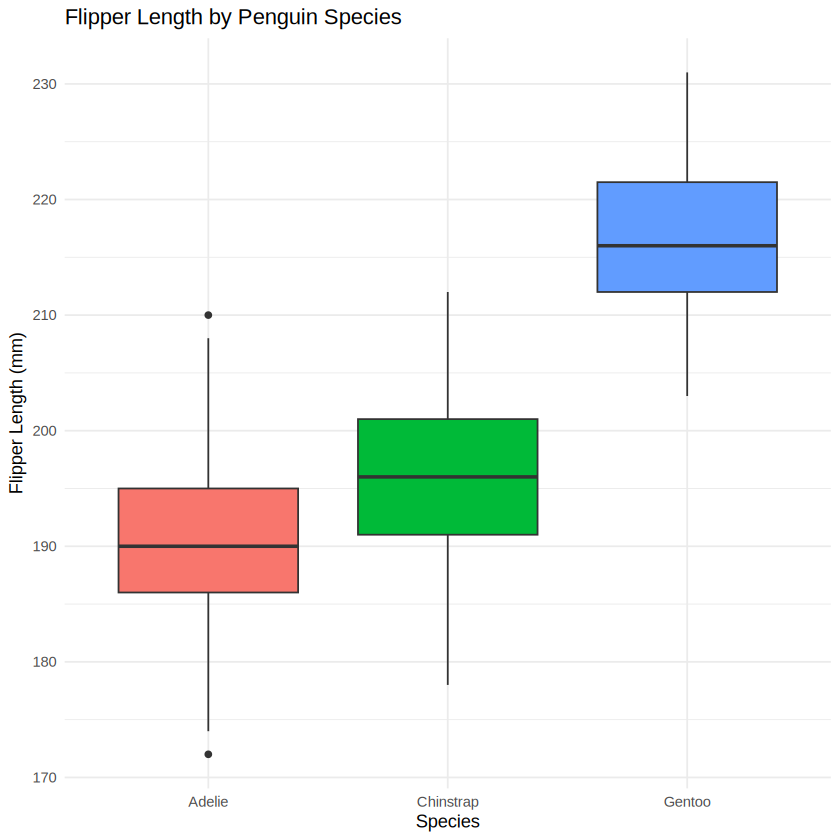

In [18]:
flipper_stats <- df %>%
  group_by(species) %>%
  summarise(
    n = n(),
    Mean = mean(flipper_length_mm),
    Median = median(flipper_length_mm),
    SD = sd(flipper_length_mm),
    Minimum = min(flipper_length_mm),
    Maximum = max(flipper_length_mm)
  )
flipper_stats

ggplot(df, aes(x = species, y = flipper_length_mm, fill = species)) +
  geom_boxplot() +
  labs(title = "Flipper Length by Penguin Species",
       x = "Species", y = "Flipper Length (mm)") +
  theme_minimal() +
  guides(fill = "none")

flipper_anova <- aov(flipper_length_mm ~ species, data = df)
summary(flipper_anova)

TukeyHSD(flipper_anova)

kruskal.test(flipper_length_mm ~ species, data = df)

## Group comparison plot

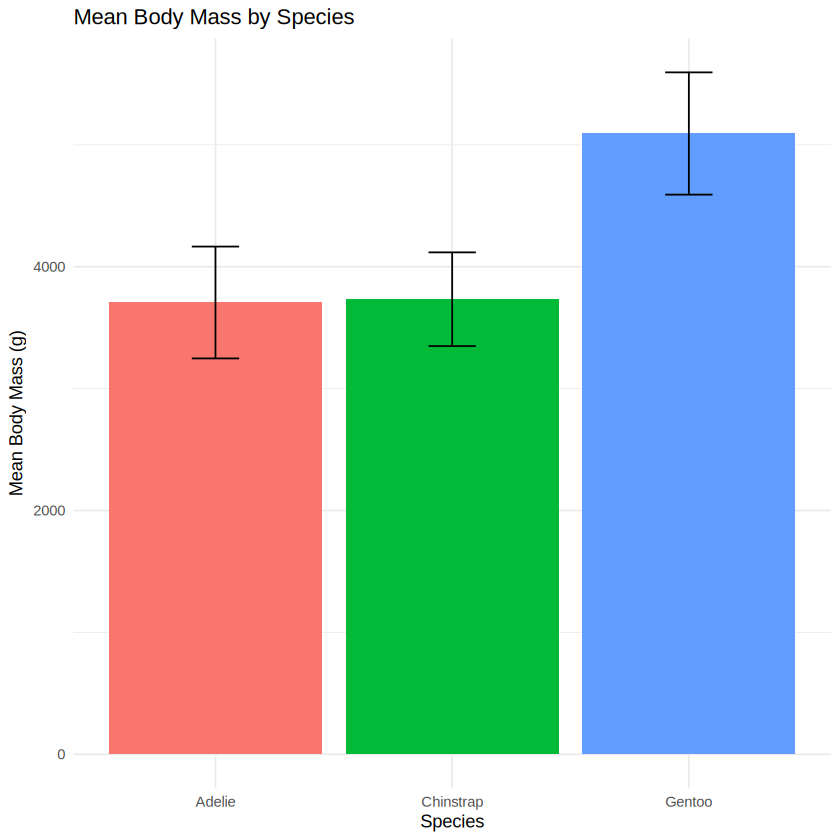

In [19]:
species_summary <- df %>%
  group_by(species) %>%
  summarise(
    mean_mass = mean(body_mass_g),
    sd_mass = sd(body_mass_g)
  )

ggplot(species_summary, aes(x = species, y = mean_mass, fill = species)) +
  geom_col() +
  geom_errorbar(aes(ymin = mean_mass - sd_mass,
                    ymax = mean_mass + sd_mass), width = 0.2) +
  labs(title = "Mean Body Mass by Species",
       x = "Species", y = "Mean Body Mass (g)") +
  theme_minimal() +
  guides(fill = "none")

## Final statistical summary

In [20]:
cat("Male vs Female t-test p-value:", t_test_result$p.value, "\n")
cat("95% CI for mean difference:", t_test_result$conf.int[1], "to", t_test_result$conf.int[2], "\n")
cat("One-way ANOVA p-value:", anova_p, "\n")
cat("Kruskal-Wallis p-value:", kruskal_p, "\n")
cat("Two-way ANOVA:\n")
print(summary(two_way_model))
cat("Flipper-length ANOVA p-value:", summary(flipper_anova)[[1]][["Pr(>F)"]][1], "\n")

Male vs Female t-test p-value: 4.793891e-16 
95% CI for mean difference: -840.5783 to -526.2453 
One-way ANOVA p-value: 3.744505e-81 
Kruskal-Wallis p-value: 8.836877e-47 
Two-way ANOVA:
             Df    Sum Sq  Mean Sq F value   Pr(>F)    
species       2 145190219 72595110 758.358  < 2e-16 ***
sex           1  37090262 37090262 387.460  < 2e-16 ***
species:sex   2   1676557   838278   8.757 0.000197 ***
Residuals   327  31302628    95727                     
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1
Flipper-length ANOVA p-value: 1.587418e-107 


## Conclusion

The analysis evaluates body mass and flipper length across penguin species and sex using descriptive and inferential statistical methods. Hypothesis testing, ANOVA, post-hoc analysis and non-parametric testing provide evidence for differences among groups. The two-way ANOVA additionally evaluates the individual and interaction effects of species and sex. Flipper-length analysis provides a second physical characteristic for comparison with body-mass findings.